# Regularized linear models — Marcus Reese

This notebook trains Ridge and Lasso for casual, registered, and total hourly rentals, then compares summed rider-group predictions with direct total predictions. See `../PROJECT_REVIEW.md` for the repository audit and methodological limitations.

**Protocol:** use the team's fixed processed split; fit scaling and one-hot encoding inside five expanding training folds; select alpha by validation RMSE in original counts; fit `log1p` targets and invert with `expm1`, clipping at zero. October–December 2012 is used for the final comparison, never alpha tuning. The team's earlier EDA already used this period for a feature choice, which limits its independence.

In [1]:
from pathlib import Path
import sys

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/linear_models.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.linear_models import run, OUTPUT
from IPython.display import display, Image, Markdown
import pandas as pd

scores = run()
display(scores.round(4))

Tuning Ridge for casual (15 alphas, 5 chronological folds)


Tuning Ridge for registered (15 alphas, 5 chronological folds)


Tuning Ridge for cnt (15 alphas, 5 chronological folds)


Tuning Lasso for casual (16 alphas, 5 chronological folds)


Tuning Lasso for registered (16 alphas, 5 chronological folds)


Tuning Lasso for cnt (16 alphas, 5 chronological folds)


model       target     alpha    CV_RMSE      RMSE       MAE    RMSLE  train_RMSE
Ridge       casual  0.001000  34.597784 26.907898 12.744267 0.594978   27.782258
Ridge   registered 10.000000  84.534943 62.154936 36.087925 0.444178   50.503949
Ridge          cnt 10.000000 104.038613 70.018902 42.969514 0.425884   66.574546
Ridge summed_total       NaN        NaN 70.625258 43.433970 0.426262         NaN
Lasso       casual  0.001000  34.585778 27.888927 13.073711 0.596938   27.565899
Lasso   registered  0.002154  79.618006 62.719053 38.078749 0.448493   52.864849
Lasso          cnt  0.002154  99.257336 74.254532 46.623819 0.433431   69.069903
Lasso summed_total       NaN        NaN 72.845124 45.422091 0.430423         NaN


,model,target,alpha,CV_RMSE,RMSE,MAE,RMSLE,train_RMSE
0,Ridge,casual,0.0010,34.5978,26.9079,12.7443,0.5950,27.7823
1,Ridge,registered,10.0000,84.5349,62.1549,36.0879,0.4442,50.5039
2,Ridge,cnt,10.0000,104.0386,70.0189,42.9695,0.4259,66.5745
3,Ridge,summed_total,NaN,NaN,70.6253,43.4340,0.4263,NaN
4,Lasso,casual,0.0010,34.5858,27.8889,13.0737,0.5969,27.5659
5,Lasso,registered,0.0022,79.6180,62.7191,38.0787,0.4485,52.8648
6,Lasso,cnt,0.0022,99.2573,74.2545,46.6238,0.4334,69.0699
7,Lasso,summed_total,NaN,NaN,72.8451,45.4221,0.4304,NaN


## Tuning and model interpretation

Smaller alpha allows more flexible coefficients; larger alpha shrinks them. Ridge shrinks coefficients continuously; Lasso can make them exactly zero. We search separate logarithmic ranges for the two objectives, keep all candidate fold scores, and flag selections at a grid boundary.

The black tuning line is the mean of chronological fold RMSEs. Folds span different seasons and growth levels, so differences among folds reflect temporal variation as well as model behavior. Coefficients act on **log1p rentals**. Numeric weather coefficients use standardized units; redundant one-hot, cyclic, and binary terms prevent a unique causal interpretation of individual coefficients.

,model,target,param_regressor__model__alpha,std_test_score,mean_validation_RMSE
0,Ridge,casual,0.001000,10.750715,34.597784
23,Ridge,registered,10.000000,8.811697,84.534943
38,Ridge,cnt,10.000000,18.635704,104.038613
51,Lasso,casual,0.001000,10.307462,34.585778
68,Lasso,registered,0.002154,10.778447,79.618006
84,Lasso,cnt,0.002154,18.872517,99.257336


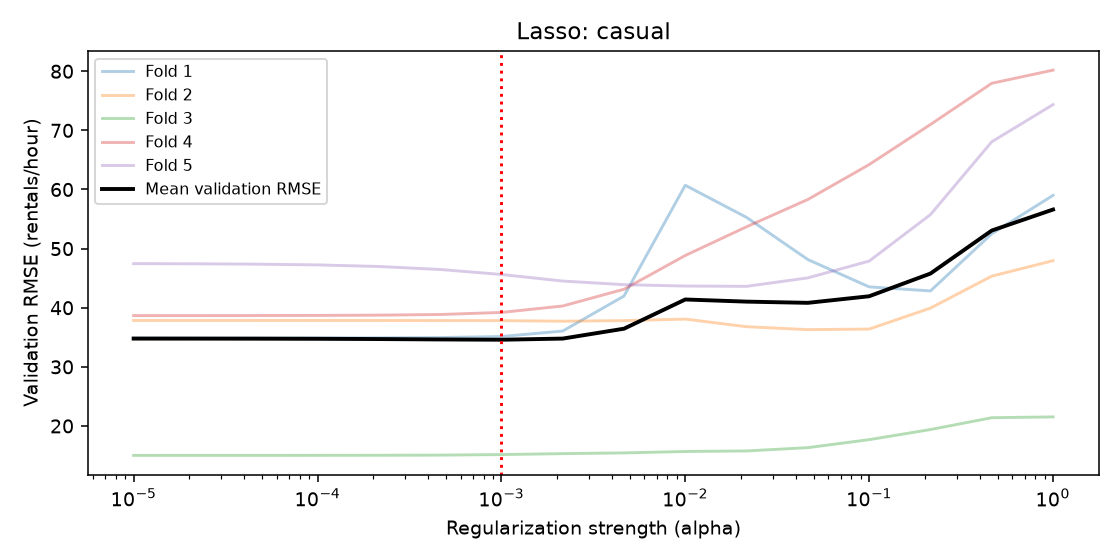

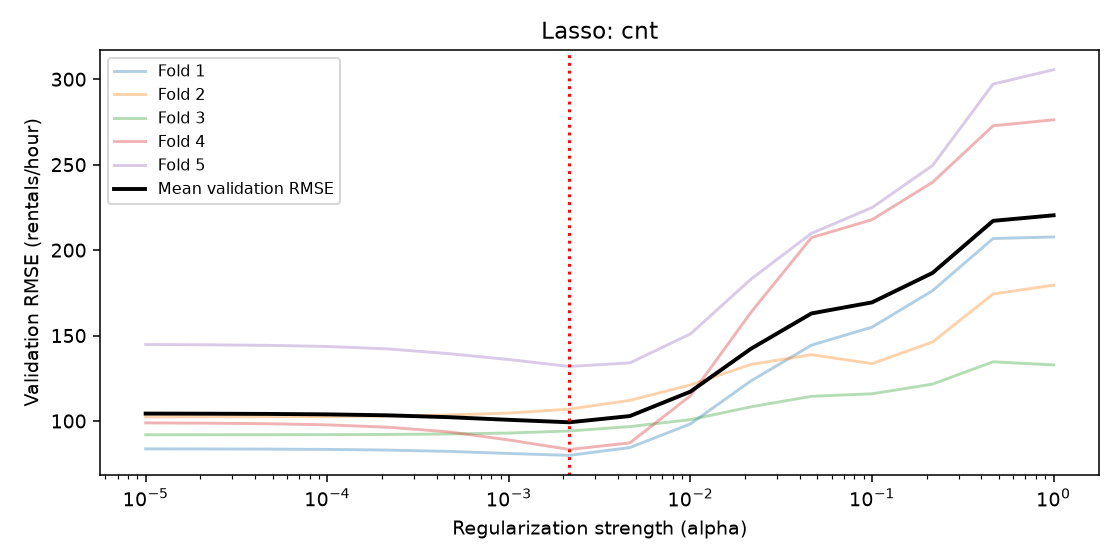

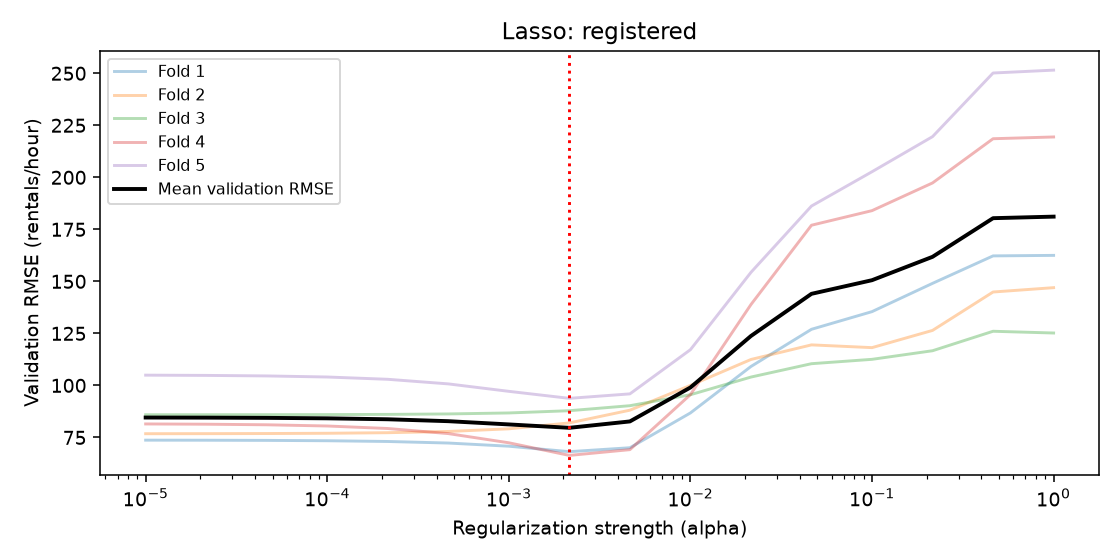

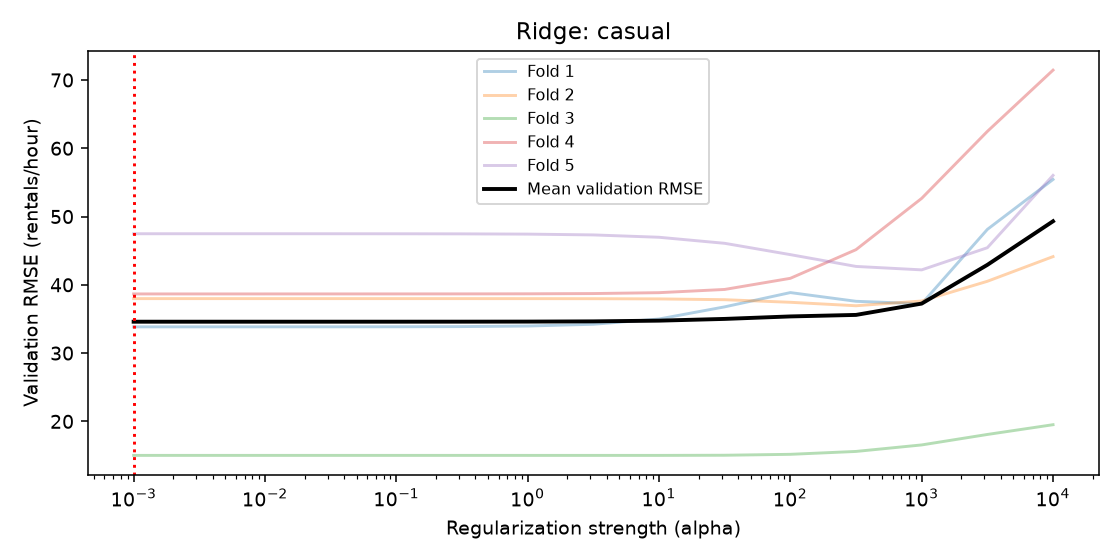

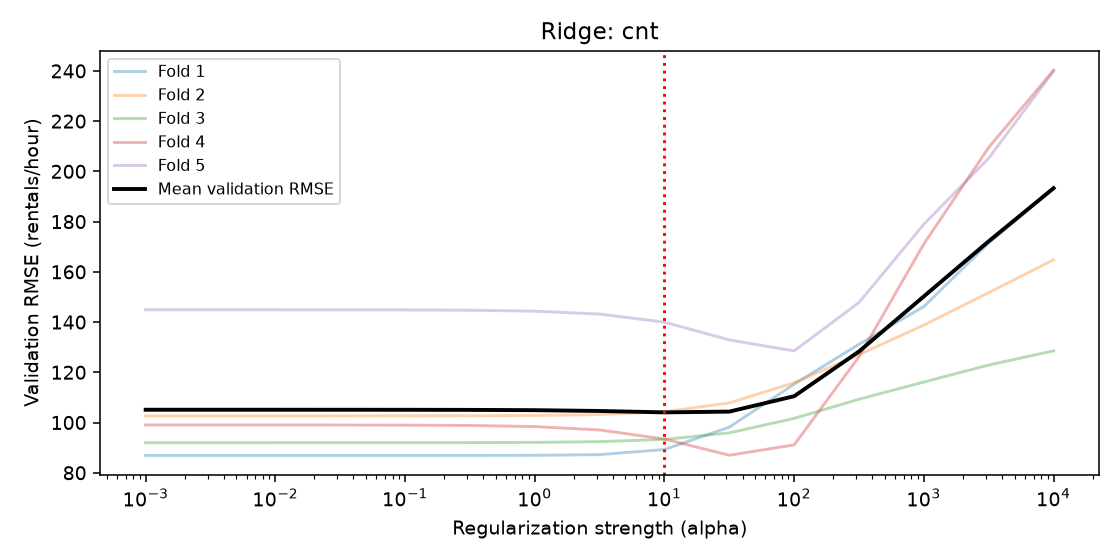

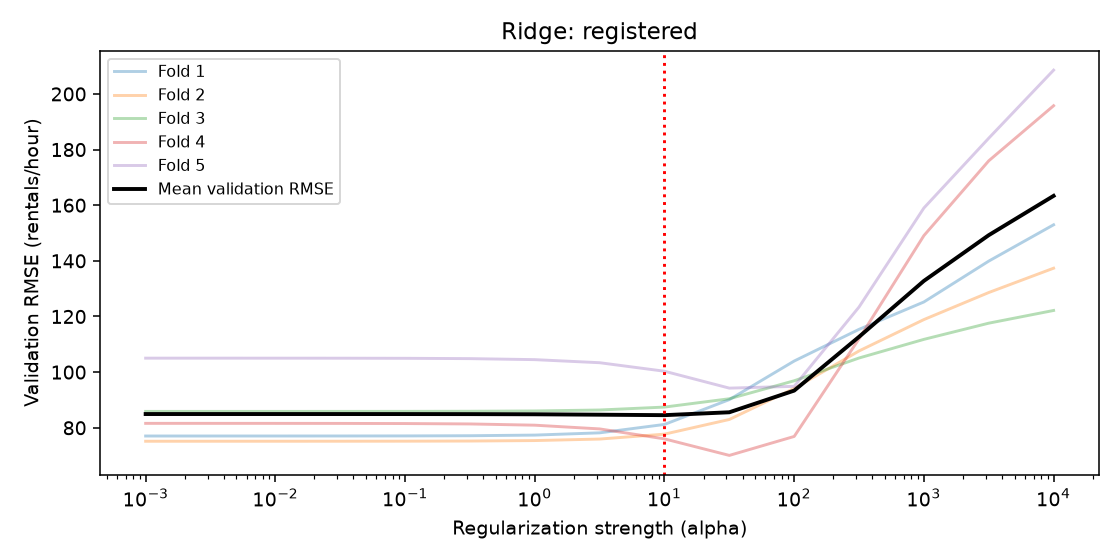

In [2]:
cv = pd.read_csv(OUTPUT / "cv_results.csv")
selected = cv.loc[cv.rank_test_score == 1, ["model", "target", "param_regressor__model__alpha", "mean_test_score", "std_test_score"]].copy()
selected["mean_validation_RMSE"] = -selected.pop("mean_test_score")
display(selected)
for path in sorted(OUTPUT.glob("*_tuning.png")):
    display(Image(filename=str(path)))

In [3]:
coef = pd.read_csv(OUTPUT / "coefficients.csv")
summary = coef.groupby(["model", "target"]).coefficient_log_scale.agg(
    features="size", nonzero=lambda x: (x.abs() > 1e-10).sum())
display(summary)
for (model, target), group in coef.groupby(["model", "target"]):
    display(Markdown(f"### {model}: {target}"))
    display(group.loc[group.coefficient_log_scale.abs().nlargest(10).index])

features  nonzero
model target                       
Lasso casual            67       56
      cnt               67       52
      registered        67       50
Ridge casual            67       67
      cnt               67       67
      registered        67       67

### Lasso: casual

,model,target,feature,coefficient_log_scale
216,Lasso,casual,hour_workday_5,-1.135095
215,Lasso,casual,hour_workday_4,-0.858645
262,Lasso,casual,hr_sin,-0.853177
239,Lasso,casual,hour_workday_28,-0.838887
243,Lasso,casual,hour_workday_32,0.822750
263,Lasso,casual,hr_cos,-0.815049
238,Lasso,casual,hour_workday_27,-0.786677
217,Lasso,casual,hour_workday_6,-0.760929
240,Lasso,casual,hour_workday_29,-0.658748
242,Lasso,casual,hour_workday_31,0.555918


### Lasso: cnt

,model,target,feature,coefficient_log_scale
377,Lasso,cnt,hour_workday_32,1.833303
372,Lasso,cnt,hour_workday_27,-1.813789
373,Lasso,cnt,hour_workday_28,-1.752228
376,Lasso,cnt,hour_workday_31,1.561409
371,Lasso,cnt,hour_workday_26,-1.440759
350,Lasso,cnt,hour_workday_5,-1.393831
349,Lasso,cnt,hour_workday_4,-1.324213
370,Lasso,cnt,hour_workday_25,-1.008733
351,Lasso,cnt,hour_workday_6,-0.919677
378,Lasso,cnt,hour_workday_33,0.879624


...

,model,target,feature,coefficient_log_scale
15,Ridge,casual,hour_workday_5,-1.078045
42,Ridge,casual,hour_workday_32,0.920831
61,Ridge,casual,hr_sin,-0.911192
62,Ridge,casual,hr_cos,-0.882511
14,Ridge,casual,hour_workday_4,-0.788860
38,Ridge,casual,hour_workday_28,-0.746414
16,Ridge,casual,hour_workday_6,-0.716465
37,Ridge,casual,hour_workday_27,-0.689357
41,Ridge,casual,hour_workday_31,0.675819
39,Ridge,casual,hour_workday_29,-0.574530


### Ridge: cnt

,model,target,feature,coefficient_log_scale
176,Ridge,cnt,hour_workday_32,1.910139
175,Ridge,cnt,hour_workday_31,1.717124
171,Ridge,cnt,hour_workday_27,-1.513902
172,Ridge,cnt,hour_workday_28,-1.489397
149,Ridge,cnt,hour_workday_5,-1.221096
170,Ridge,cnt,hour_workday_26,-1.129509
148,Ridge,cnt,hour_workday_4,-1.102504
174,Ridge,cnt,hour_workday_30,0.973822
195,Ridge,cnt,hr_sin,-0.948378
177,Ridge,cnt,hour_workday_33,0.907401


### Ridge: registered

,model,target,feature,coefficient_log_scale
109,Ridge,registered,hour_workday_32,2.003051
108,Ridge,registered,hour_workday_31,1.796774
104,Ridge,registered,hour_workday_27,-1.571415
105,Ridge,registered,hour_workday_28,-1.518696
103,Ridge,registered,hour_workday_26,-1.261333
82,Ridge,registered,hour_workday_5,-1.165186
81,Ridge,registered,hour_workday_4,-1.124063
107,Ridge,registered,hour_workday_30,1.041808
110,Ridge,registered,hour_workday_33,0.964738
128,Ridge,registered,hr_sin,-0.922607


## Test diagnostics and total-demand comparison

Residuals are actual minus predicted; positive values indicate underprediction. Compare scatterplots with the identity line and inspect peak errors and temporal structure. The daily plot shows mean hourly demand among **observed** hours; it does not invent missing Hurricane Sandy observations.

Compare `cnt` and `summed_total` within each family on identical hours. Lower RMSE/MAE means less error in rental counts. Cross-group absolute errors have different target scales; RMSLE provides an additional relative-scale perspective. Results here do not establish which teammate's model family wins.

,model,target,alpha,CV_RMSE,RMSE,MAE,RMSLE,train_RMSE
2,Ridge,cnt,10.0000,104.0386,70.0189,42.9695,0.4259,66.5745
3,Ridge,summed_total,NaN,NaN,70.6253,43.4340,0.4263,NaN
6,Lasso,cnt,0.0022,99.2573,74.2545,46.6238,0.4334,69.0699
7,Lasso,summed_total,NaN,NaN,72.8451,45.4221,0.4304,NaN


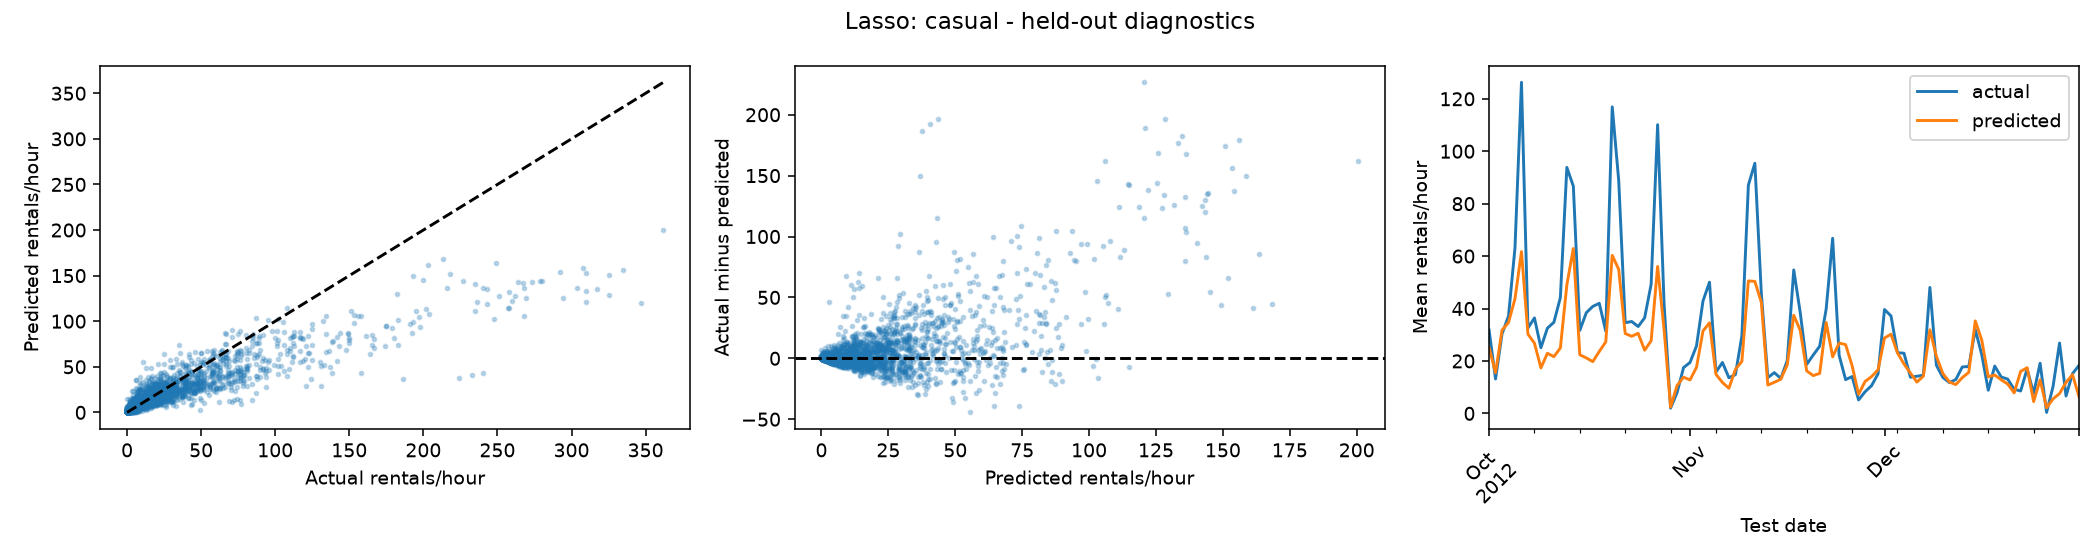

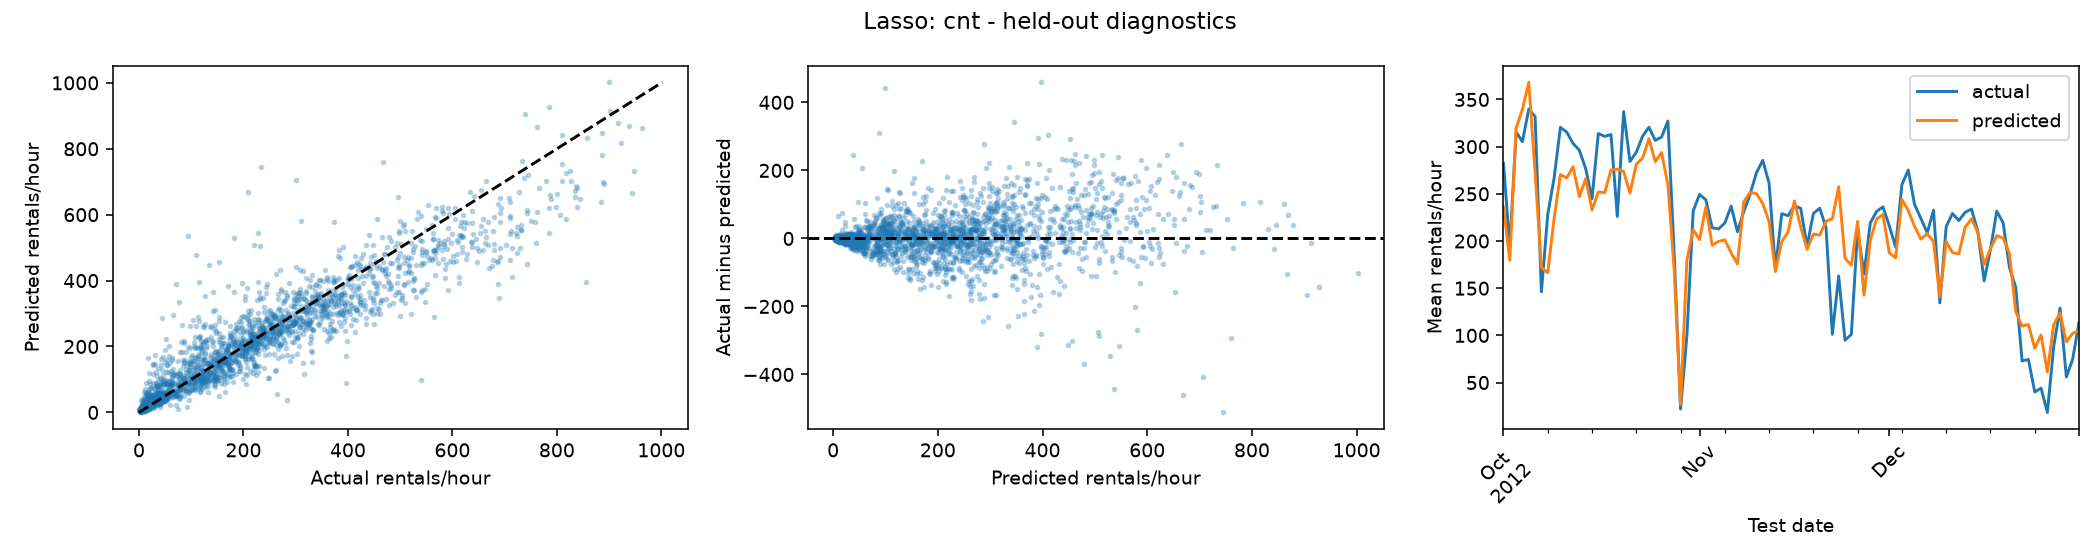

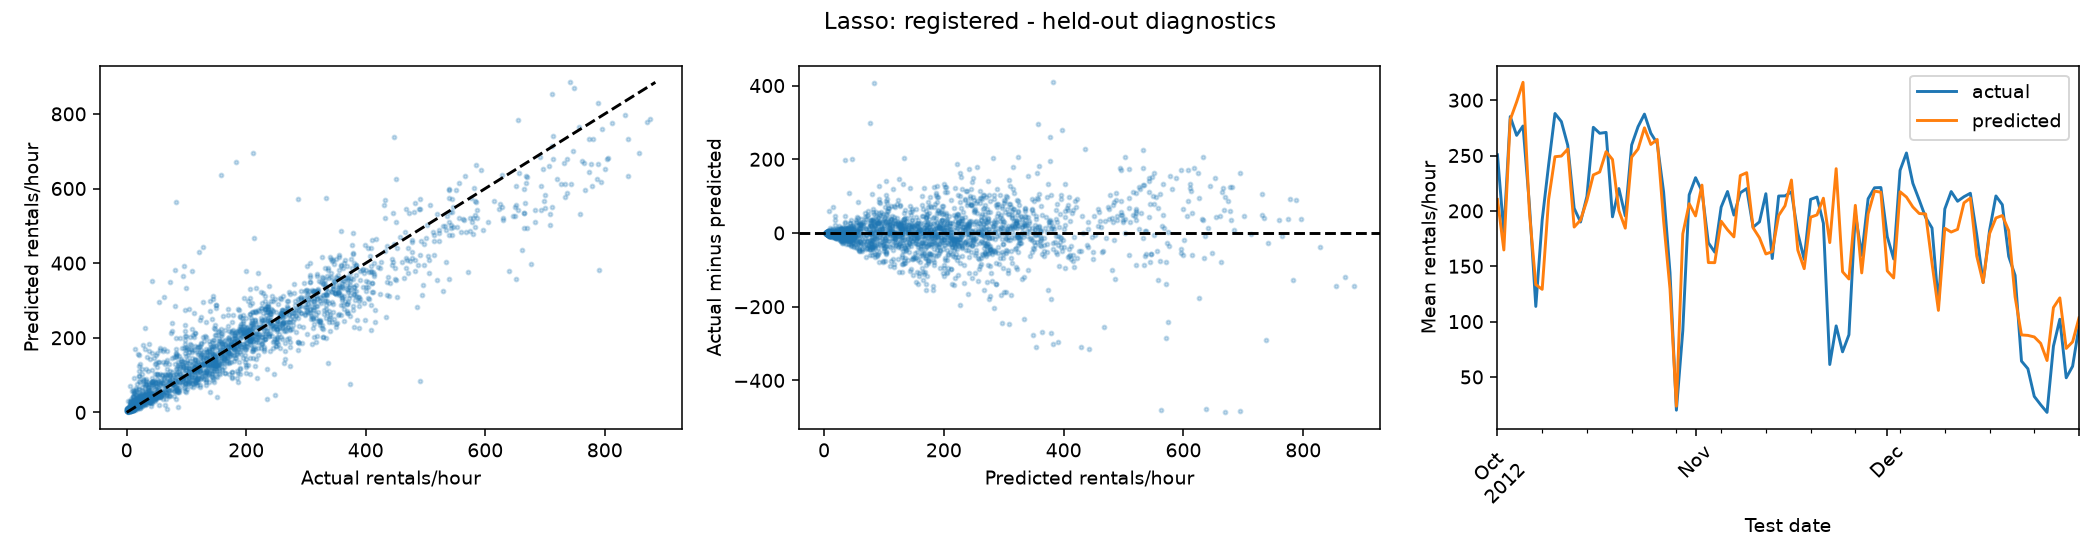

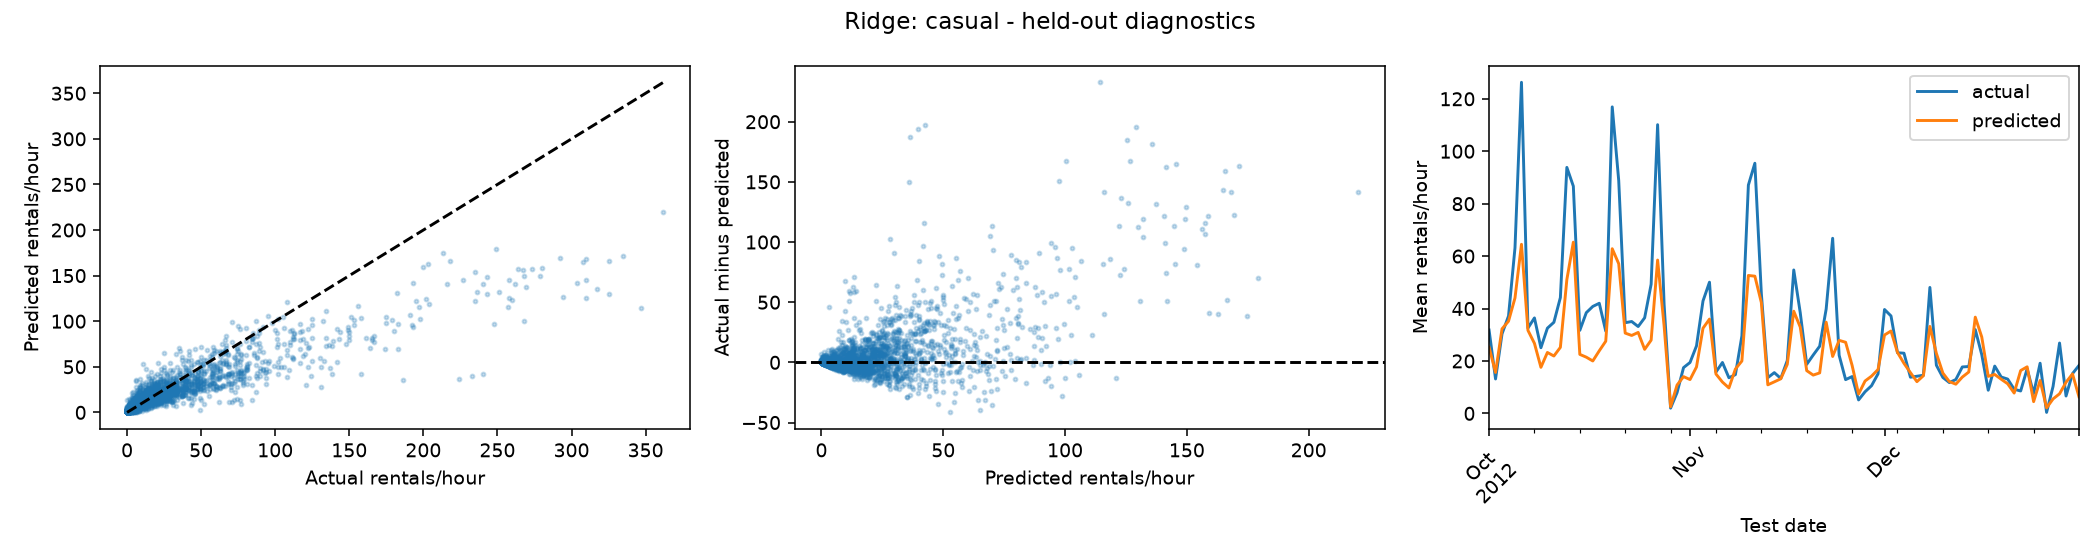

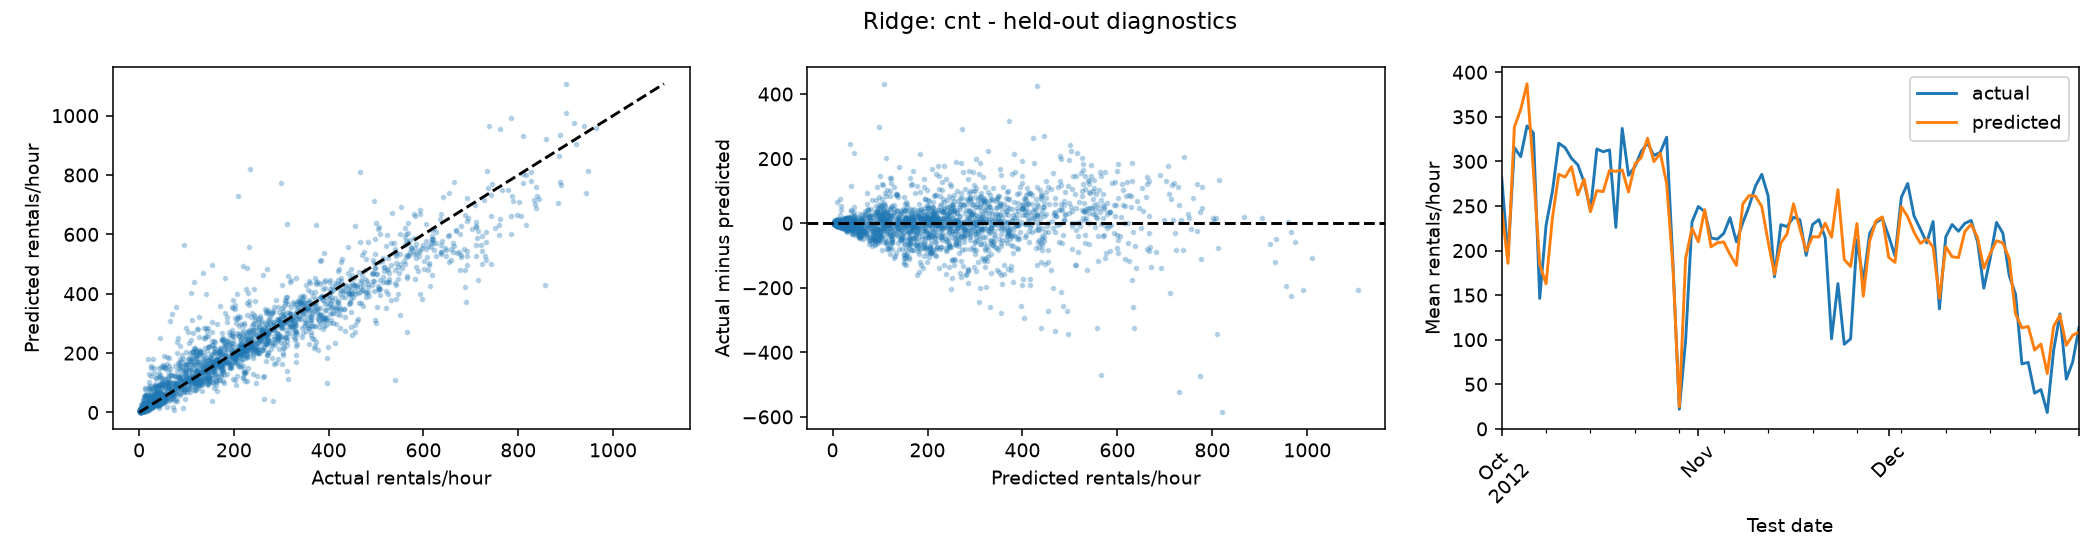

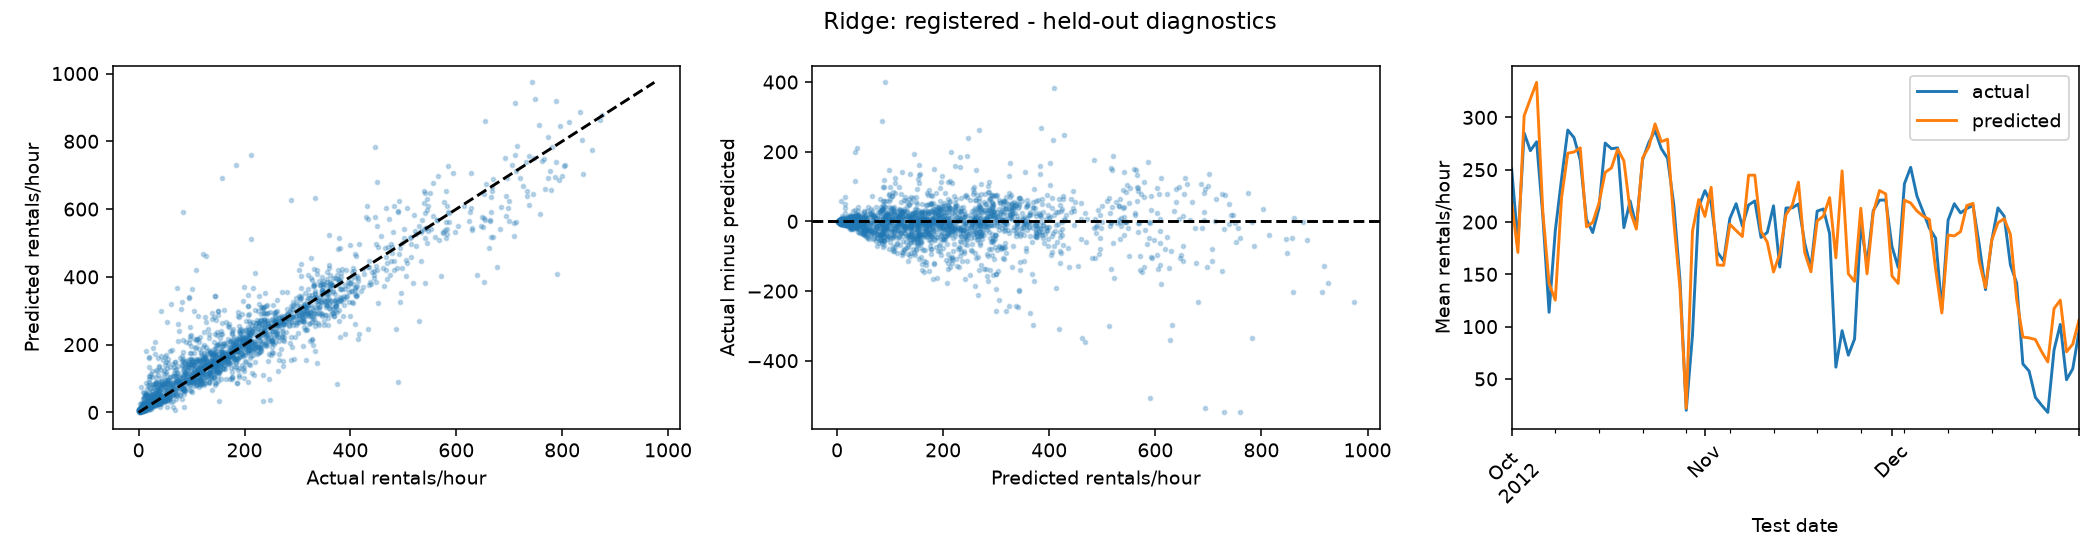

In [4]:
display(scores[scores.target.isin(["cnt", "summed_total"])].round(4))
for path in sorted(OUTPUT.glob("*_diagnostics.png")):
    display(Image(filename=str(path)))

## Team handoff

`linear_models/` contains all CV results, fold boundaries, six sets of coefficients, final scores, aligned test predictions, diagnostic plots, model files, and a version/data-hash manifest. Use the test predictions for final comparison, **not** as training inputs for stacking. Training an ensemble requires a separate chronological out-of-fold protocol.

Interpret the diagnostics in your own words and review `linear_models/REPORT.md` for the measured results and caveats.